# Internal Assignment-02: Comparative Study and Implementation of Generative AI Models
AE and VAE (CO3: reconstruction)  |  DCGAN and pretrained Diffusion (CO4: generation)

Dataset : CIFAR-10 (10,000 images, 32x32 RGB, auto-downloaded by Keras)
Models  : AE, VAE, DCGAN trained from scratch (TensorFlow/Keras)
          Diffusion = pretrained segmind/tiny-sd (Hugging Face Diffusers, inference only)

HOW TO RUN (Google Colab)
  1. Runtime > Change runtime type > T4 GPU
  2. Paste each "# %%" block into its own cell, run top to bottom
  3. Screenshot every plot (also saved in ./outputs) and copy the numbers
     printed in the final SUMMARY cell into your report tables.

In [4]:
# CELL 1: Install (run once in Colab, remove the leading "#")
!pip install -q diffusers transformers accelerate safetensors

In [5]:
# CELL 2: Imports, settings, helpers
import os, time, json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

os.makedirs("outputs", exist_ok=True)
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

N_IMAGES = 10000        # images kept from CIFAR-10
IMG = 32                # image size
LATENT_DIM = 128        # AE and VAE bottleneck
NOISE_DIM = 100         # DCGAN noise vector
EPOCHS_AE = 15
EPOCHS_VAE = 15
EPOCHS_GAN = 40
BATCH = 128
SD_MODEL = "segmind/tiny-sd"
SD_STEPS = 20
SD_GUIDANCE = 7.0

# OPTIONAL (Activity A): your own input image. Upload it in Colab (left Files panel)
# and set e.g. CUSTOM_IMAGE_PATH = "my_photo.jpg". It is resized to 32x32.
CUSTOM_IMAGE_PATH = None

timings = {}   # filled while running, printed in the summary
results = {}


def show_grid(imgs, nrow, ncol, title=None, path=None, size=1.6):
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * size, nrow * size + 0.4))
    axes = np.array(axes).reshape(nrow, ncol)
    for i in range(nrow):
        for j in range(ncol):
            axes[i, j].imshow(np.clip(imgs[i * ncol + j], 0, 1))
            axes[i, j].axis("off")
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    if path:
        plt.savefig(path, dpi=150)
    plt.show()

TensorFlow: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


All: (10000, 32, 32, 3) | Train: (9000, 32, 32, 3) | Validation: (1000, 32, 32, 3)


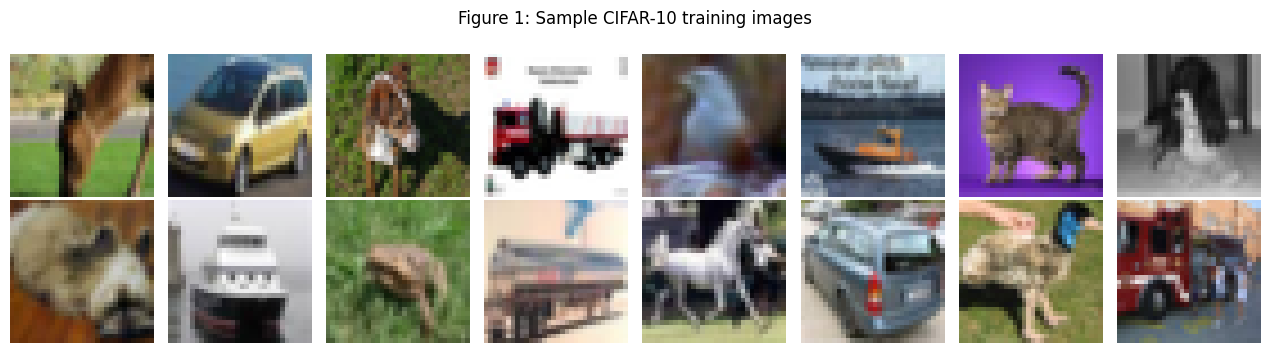

In [6]:
# CELL 3: Dataset (Section 2 of the report)
(x_all, _), _ = keras.datasets.cifar10.load_data()
rng = np.random.default_rng(SEED)
idx = rng.permutation(len(x_all))[:N_IMAGES]
x_all = x_all[idx].astype("float32") / 255.0            # shape (10000, 32, 32, 3), range [0, 1]
split = int(0.9 * N_IMAGES)
x_train, x_val = x_all[:split], x_all[split:]
print("All:", x_all.shape, "| Train:", x_train.shape, "| Validation:", x_val.shape)
show_grid(x_train[:16], 2, 8, "Figure 1: Sample CIFAR-10 training images", "outputs/fig1_samples.png")

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │       264,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 64)       │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 16)     │         4,624 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 3)      │           435 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 717,027 (2.74 MB)

 Trainable params: 717,027 (2.74 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
71/71 - 26s - 373ms/step - loss: 0.0475 - val_loss: 0.0265
Epoch 2/15
71/71 - 1s - 10ms/step - loss: 0.0223 - val_loss: 0.0200
Epoch 3/15
71/71 - 1s - 14ms/step - loss: 0.0179 - val_loss: 0.0170
Epoch 4/15
71/71 - 1s - 16ms/step - loss: 0.0162 - val_loss: 0.0156
Epoch 5/15
71/71 - 1s - 16ms/step - loss: 0.0148 - val_loss: 0.0148
Epoch 6/15
71/71 - 1s - 15ms/step - loss: 0.0142 - val_loss: 0.0134
Epoch 7/15
71/71 - 1s - 14ms/step - loss: 0.0122 - val_loss: 0.0116
Epoch 8/15
71/71 - 1s - 9ms/step - loss: 0.0108 - val_loss: 0.0108
Epoch 9/15
71/71 - 1s - 9ms/step - loss: 0.0104 - val_loss: 0.0104
Epoch 10/15
71/71 - 1s - 10ms/step - loss: 0.0097 - val_loss: 0.0099
Epoch 11/15
71/71 - 1s - 19ms/step - loss: 0.0094 - val_loss: 0.0097
Epoch 12/15
71/71 - 1s - 11ms/step - loss: 0.0091 - val_loss: 0.0096
Epoch 13/15
71/71 - 1s - 10ms/step - loss: 0.0087 - val_loss: 0.0092
Epoch 14/15
71/71 - 1s - 9ms/step - loss: 0.0084 - val_loss: 0.0092
Epoch 15/15
71/71 - 1s - 9ms/step - loss: 0.

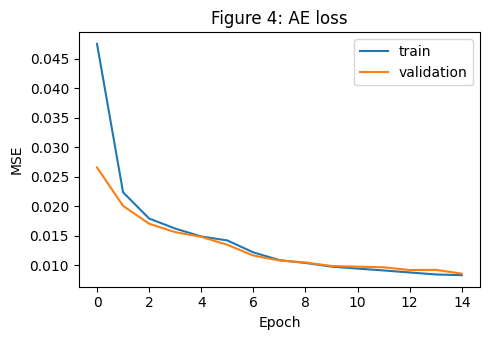

In [7]:
# CELL 4: Autoencoder (Section 3.1)
def build_ae():
    inp = keras.Input((IMG, IMG, 3))
    x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(inp)   # 16
    x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)     # 8
    x = layers.Conv2D(128, 3, strides=2, padding="same", activation="relu")(x)    # 4
    x = layers.Flatten()(x)
    z = layers.Dense(LATENT_DIM, name="latent")(x)
    d = layers.Dense(4 * 4 * 128, activation="relu")(z)
    d = layers.Reshape((4, 4, 128))(d)
    d = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(d)   # 8
    d = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(d)   # 16
    d = layers.Conv2DTranspose(16, 3, strides=2, padding="same", activation="relu")(d)   # 32
    out = layers.Conv2D(3, 3, padding="same", activation="sigmoid")(d)
    return keras.Model(inp, out, name="autoencoder")


ae = build_ae()
ae.summary()
ae.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")

t0 = time.time()
hist_ae = ae.fit(x_train, x_train, validation_data=(x_val, x_val),
                 epochs=EPOCHS_AE, batch_size=BATCH, verbose=2)
timings["AE training (s)"] = round(time.time() - t0, 1)
results["AE train loss first->last"] = (round(hist_ae.history["loss"][0], 4), round(hist_ae.history["loss"][-1], 4))
results["AE val loss first->last"] = (round(hist_ae.history["val_loss"][0], 4), round(hist_ae.history["val_loss"][-1], 4))
print(timings["AE training (s)"], "s |", results["AE val loss first->last"])

plt.figure(figsize=(5, 3.5))
plt.plot(hist_ae.history["loss"], label="train")
plt.plot(hist_ae.history["val_loss"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("Figure 4: AE loss"); plt.legend()
plt.tight_layout(); plt.savefig("outputs/fig4_ae_loss.png", dpi=150); plt.show()

Epoch 1/15
71/71 - 15s - 208ms/step - kl: 1.9345 - loss: 700.6935 - recon: 698.7589 - val_kl: 4.7194 - val_loss: 686.5132 - val_recon: 681.7938
Epoch 2/15
71/71 - 1s - 11ms/step - kl: 7.0830 - loss: 673.2673 - recon: 666.1844 - val_kl: 9.1961 - val_loss: 661.2673 - val_recon: 652.0712
Epoch 3/15
71/71 - 1s - 9ms/step - kl: 11.0171 - loss: 655.5223 - recon: 644.5054 - val_kl: 11.8183 - val_loss: 653.5206 - val_recon: 641.7023
Epoch 4/15
71/71 - 1s - 9ms/step - kl: 12.5962 - loss: 651.9069 - recon: 639.3106 - val_kl: 12.6029 - val_loss: 652.2257 - val_recon: 639.6228
Epoch 5/15
71/71 - 1s - 9ms/step - kl: 13.7394 - loss: 648.9883 - recon: 635.2490 - val_kl: 14.4920 - val_loss: 650.3057 - val_recon: 635.8137
Epoch 6/15
71/71 - 1s - 9ms/step - kl: 14.2377 - loss: 645.8555 - recon: 631.6178 - val_kl: 14.1108 - val_loss: 644.9620 - val_recon: 630.8513
Epoch 7/15
71/71 - 1s - 9ms/step - kl: 14.0336 - loss: 642.4612 - recon: 628.4277 - val_kl: 14.3337 - val_loss: 642.1185 - val_recon: 627.7849

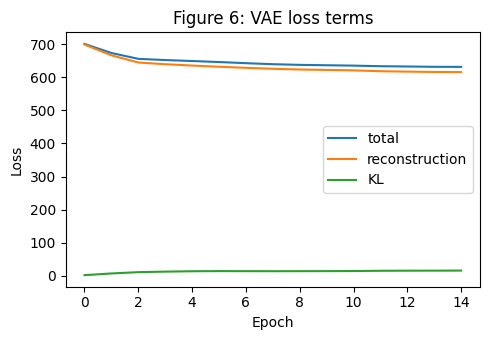

In [8]:
# CELL 5: Variational Autoencoder (Section 3.2)
class Sampling(layers.Layer):
    """Reparameterization trick: z = mu + sigma * eps, eps ~ N(0, I)."""
    def call(self, inputs):
        mu, logvar = inputs
        eps = tf.random.normal(tf.shape(mu))
        return mu + tf.exp(0.5 * logvar) * eps


def build_vae_parts():
    enc_in = keras.Input((IMG, IMG, 3))
    x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(enc_in)
    x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2D(128, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Flatten()(x)
    mu = layers.Dense(LATENT_DIM, name="mu")(x)
    logvar = layers.Dense(LATENT_DIM, name="logvar")(x)
    z = Sampling()([mu, logvar])
    encoder = keras.Model(enc_in, [mu, logvar, z], name="vae_encoder")

    dec_in = keras.Input((LATENT_DIM,))
    d = layers.Dense(4 * 4 * 128, activation="relu")(dec_in)
    d = layers.Reshape((4, 4, 128))(d)
    d = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(d)
    d = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(d)
    d = layers.Conv2DTranspose(16, 3, strides=2, padding="same", activation="relu")(d)
    out = layers.Conv2D(3, 3, padding="same", activation="sigmoid")(d)
    decoder = keras.Model(dec_in, out, name="vae_decoder")
    return encoder, decoder


class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kw):
        super().__init__(**kw)
        self.encoder, self.decoder = encoder, decoder
        self.total_m = keras.metrics.Mean(name="loss")
        self.rec_m = keras.metrics.Mean(name="recon")
        self.kl_m = keras.metrics.Mean(name="kl")

    @property
    def metrics(self):
        return [self.total_m, self.rec_m, self.kl_m]

    def _loss(self, x):
        mu, logvar, z = self.encoder(x)
        recon = self.decoder(z)
        # summed binary cross-entropy over all pixels, averaged over batch
        rec = tf.reduce_mean(tf.reduce_sum(keras.losses.binary_crossentropy(x, recon), axis=(1, 2)))
        kl = tf.reduce_mean(-0.5 * tf.reduce_sum(1 + logvar - tf.square(mu) - tf.exp(logvar), axis=1))
        return rec + kl, rec, kl

    def train_step(self, x):
        if isinstance(x, tuple):
            x = x[0]
        with tf.GradientTape() as tape:
            total, rec, kl = self._loss(x)
        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_m.update_state(total); self.rec_m.update_state(rec); self.kl_m.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, x):
        if isinstance(x, tuple):
            x = x[0]
        total, rec, kl = self._loss(x)
        self.total_m.update_state(total); self.rec_m.update_state(rec); self.kl_m.update_state(kl)
        return {m.name: m.result() for m in self.metrics}


enc, dec = build_vae_parts()
vae = VAE(enc, dec)
vae.compile(optimizer=keras.optimizers.Adam(1e-3))

t0 = time.time()
hist_vae = vae.fit(x_train, validation_data=(x_val,), epochs=EPOCHS_VAE, batch_size=BATCH, verbose=2)
timings["VAE training (s)"] = round(time.time() - t0, 1)
results["VAE final total / recon / KL"] = (round(hist_vae.history["loss"][-1], 2),
                                          round(hist_vae.history["recon"][-1], 2),
                                          round(hist_vae.history["kl"][-1], 2))
print(timings["VAE training (s)"], "s |", results["VAE final total / recon / KL"])

plt.figure(figsize=(5, 3.5))
plt.plot(hist_vae.history["loss"], label="total")
plt.plot(hist_vae.history["recon"], label="reconstruction")
plt.plot(hist_vae.history["kl"], label="KL")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Figure 6: VAE loss terms"); plt.legend()
plt.tight_layout(); plt.savefig("outputs/fig6_vae_loss.png", dpi=150); plt.show()

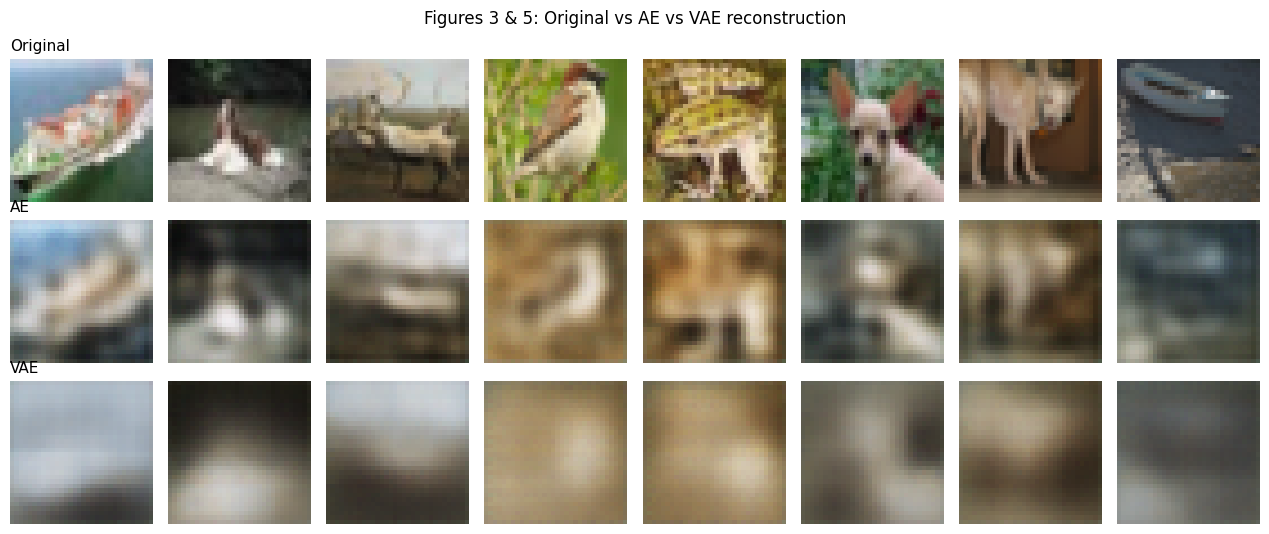

AE  (MSE, PSNR dB, SSIM): (0.00855, 21.15, 0.6502)
VAE (MSE, PSNR dB, SSIM): (0.02141, 17.05, 0.3429)


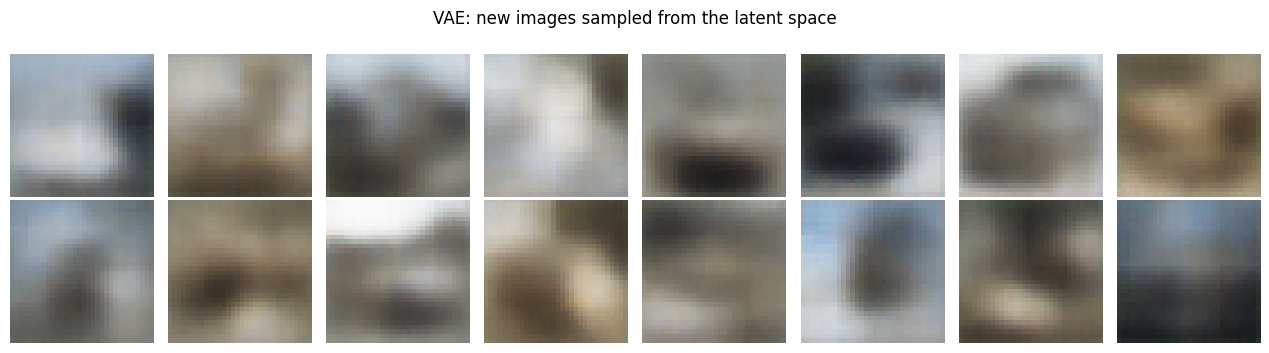

In [9]:
# CELL 6: Activity A - Reconstruction (CO3): screenshots + metrics
def load_custom(path):
    img = keras.utils.load_img(path, target_size=(IMG, IMG))
    return (np.array(img, dtype="float32") / 255.0)[None]


def vae_reconstruct(x):
    mu, _, _ = vae.encoder(x)           # use the mean (no sampling noise) for reconstruction
    return vae.decoder(mu).numpy()


N_SHOW = 8
test_imgs = x_val[:N_SHOW]
rec_ae = ae.predict(test_imgs, verbose=0)
rec_vae = vae_reconstruct(test_imgs)

# Figure: original / AE / VAE rows (this is the screenshot for the report)
fig, axes = plt.subplots(3, N_SHOW, figsize=(N_SHOW * 1.6, 5.4))
for r, (imgs, name) in enumerate([(test_imgs, "Original"), (rec_ae, "AE"), (rec_vae, "VAE")]):
    for c in range(N_SHOW):
        axes[r, c].imshow(np.clip(imgs[c], 0, 1)); axes[r, c].axis("off")
    axes[r, 0].set_title(name, loc="left", fontsize=11)
plt.suptitle("Figures 3 & 5: Original vs AE vs VAE reconstruction")
plt.tight_layout(); plt.savefig("outputs/fig3_5_reconstruction.png", dpi=150); plt.show()

# Optional single custom input image
if CUSTOM_IMAGE_PATH:
    custom = load_custom(CUSTOM_IMAGE_PATH)
    c_ae, c_vae = ae.predict(custom, verbose=0), vae_reconstruct(custom)
    fig, axes = plt.subplots(1, 3, figsize=(7, 2.8))
    for ax, im, t in zip(axes, [custom[0], c_ae[0], c_vae[0]], ["Input", "AE", "VAE"]):
        ax.imshow(np.clip(im, 0, 1)); ax.set_title(t); ax.axis("off")
    plt.tight_layout(); plt.savefig("outputs/activityA_custom_input.png", dpi=150); plt.show()

# Quantitative comparison on the whole validation set (MSE, PSNR, SSIM)
def metrics(orig, rec):
    mse = float(np.mean((orig - rec) ** 2))
    psnr = float(tf.reduce_mean(tf.image.psnr(orig, rec, max_val=1.0)))
    ssim = float(tf.reduce_mean(tf.image.ssim(orig, rec, max_val=1.0)))
    return round(mse, 5), round(psnr, 2), round(ssim, 4)


full_ae = ae.predict(x_val, verbose=0)
full_vae = vae_reconstruct(x_val)
results["AE  (MSE, PSNR dB, SSIM)"] = metrics(x_val, full_ae)
results["VAE (MSE, PSNR dB, SSIM)"] = metrics(x_val, full_vae)
print("AE  (MSE, PSNR dB, SSIM):", results["AE  (MSE, PSNR dB, SSIM)"])
print("VAE (MSE, PSNR dB, SSIM):", results["VAE (MSE, PSNR dB, SSIM)"])

# Extra: VAE can sample brand-new images from N(0, I)
z = tf.random.normal((16, LATENT_DIM))
show_grid(vae.decoder(z).numpy(), 2, 8, "VAE: new images sampled from the latent space",
          "outputs/activityA_vae_samples.png")

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 4096)           │       409,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 4096)           │        16,384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_6              │ (None, 8, 8, 128)      │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_7              │ (None, 16, 16, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 32, 32, 3)      │         3,075 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,085,187 (4.14 MB)

 Trainable params: 1,076,611 (4.11 MB)

 Non-trainable params: 8,576 (33.50 KB)

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gaussian_noise (GaussianNoise)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 64)     │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 4, 4, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 664,513 (2.53 MB)

 Trainable params: 663,745 (2.53 MB)

 Non-trainable params: 768 (3.00 KB)

Epoch 01/40 | G loss 2.3463 | D loss 0.7218
Epoch 05/40 | G loss 2.8953 | D loss 0.6224
Epoch 10/40 | G loss 2.9457 | D loss 0.6529
Epoch 15/40 | G loss 2.6669 | D loss 0.6577
Epoch 20/40 | G loss 2.8076 | D loss 0.6062
Epoch 25/40 | G loss 2.4828 | D loss 0.7294
Epoch 30/40 | G loss 2.2681 | D loss 0.7704
Epoch 35/40 | G loss 2.7368 | D loss 0.6251
Epoch 40/40 | G loss 2.8417 | D loss 0.6063
110.7 s | (2.8417, 0.6063)


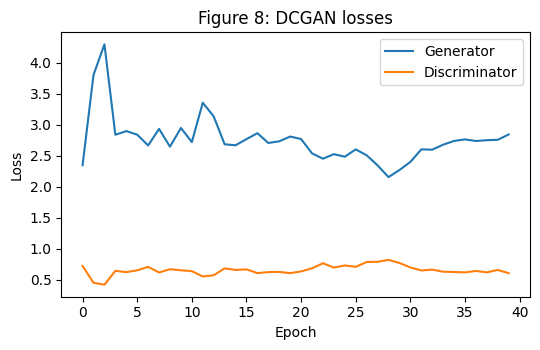

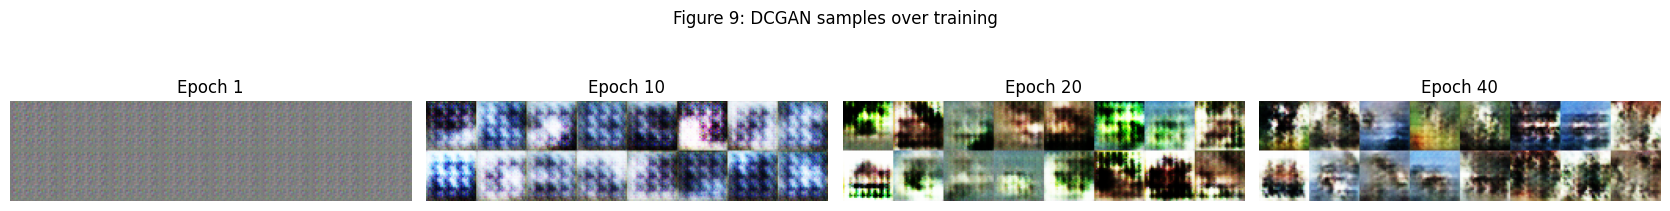

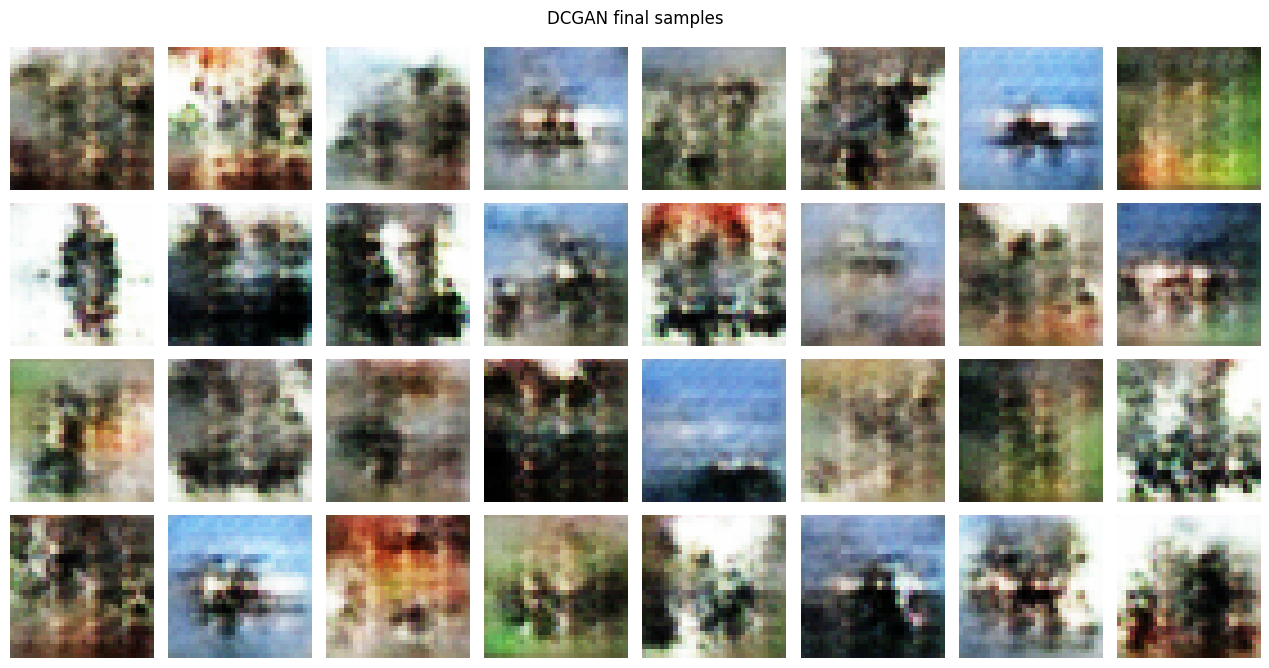

In [10]:
# CELL 7: DCGAN (Section 3.3, Activity B part 1)
x_gan = (x_train * 2.0 - 1.0).astype("float32")      # DCGAN uses [-1, 1] (tanh output)
gan_ds = tf.data.Dataset.from_tensor_slices(x_gan).shuffle(5000, seed=SEED).batch(BATCH, drop_remainder=True)


def build_generator():
    return keras.Sequential([
        keras.Input((NOISE_DIM,)),
        layers.Dense(4 * 4 * 256, use_bias=False),
        layers.BatchNormalization(), layers.ReLU(),
        layers.Reshape((4, 4, 256)),
        layers.Conv2DTranspose(128, 4, strides=2, padding="same", use_bias=False),  # 8
        layers.BatchNormalization(), layers.ReLU(),
        layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False),   # 16
        layers.BatchNormalization(), layers.ReLU(),
        layers.Conv2DTranspose(3, 4, strides=2, padding="same", activation="tanh"), # 32
    ], name="generator")


def build_discriminator():
    return keras.Sequential([
        keras.Input((IMG, IMG, 3)),
        layers.GaussianNoise(0.05),                                   # input noise
        layers.Conv2D(64, 4, strides=2, padding="same"), layers.LeakyReLU(0.2),
        layers.Dropout(0.3),
        layers.Conv2D(128, 4, strides=2, padding="same"),
        layers.BatchNormalization(), layers.LeakyReLU(0.2), layers.Dropout(0.3),
        layers.Conv2D(256, 4, strides=2, padding="same"),
        layers.BatchNormalization(), layers.LeakyReLU(0.2), layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(1),                                              # logits
    ], name="discriminator")


G, D = build_generator(), build_discriminator()
G.summary(); D.summary()
bce = keras.losses.BinaryCrossentropy(from_logits=True)
g_opt = keras.optimizers.Adam(2e-4, beta_1=0.5)
d_opt = keras.optimizers.Adam(2e-4, beta_1=0.5)


@tf.function
def gan_step(real):
    b = tf.shape(real)[0]
    noise = tf.random.normal((b, NOISE_DIM))
    with tf.GradientTape() as gt, tf.GradientTape() as dt:
        fake = G(noise, training=True)
        real_out = D(real, training=True)
        fake_out = D(fake, training=True)
        # label smoothing: real labels = 0.9 instead of 1.0
        d_loss = bce(tf.ones_like(real_out) * 0.9, real_out) + bce(tf.zeros_like(fake_out), fake_out)
        g_loss = bce(tf.ones_like(fake_out), fake_out)
    d_opt.apply_gradients(zip(dt.gradient(d_loss, D.trainable_variables), D.trainable_variables))
    g_opt.apply_gradients(zip(gt.gradient(g_loss, G.trainable_variables), G.trainable_variables))
    return g_loss, d_loss


fixed_noise = tf.random.normal((16, NOISE_DIM), seed=SEED)
g_hist, d_hist, snaps = [], [], {}
snap_epochs = {1, EPOCHS_GAN // 4, EPOCHS_GAN // 2, EPOCHS_GAN}

t0 = time.time()
for epoch in range(1, EPOCHS_GAN + 1):
    gl, dl, n = 0.0, 0.0, 0
    for batch in gan_ds:
        g, d = gan_step(batch)
        gl += float(g); dl += float(d); n += 1
    g_hist.append(gl / n); d_hist.append(dl / n)
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/{EPOCHS_GAN} | G loss {g_hist[-1]:.4f} | D loss {d_hist[-1]:.4f}")
    if epoch in snap_epochs:
        snaps[epoch] = (G(fixed_noise, training=False).numpy() + 1) / 2
timings["DCGAN training (s)"] = round(time.time() - t0, 1)
results["DCGAN final G / D loss"] = (round(g_hist[-1], 4), round(d_hist[-1], 4))
print(timings["DCGAN training (s)"], "s |", results["DCGAN final G / D loss"])

# Loss curves (Figure 8)
plt.figure(figsize=(5.5, 3.6))
plt.plot(g_hist, label="Generator"); plt.plot(d_hist, label="Discriminator")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Figure 8: DCGAN losses"); plt.legend()
plt.tight_layout(); plt.savefig("outputs/fig8_dcgan_loss.png", dpi=150); plt.show()

# Samples across training (Figure 9)
fig, axes = plt.subplots(1, len(snaps), figsize=(4.2 * len(snaps), 2.6))
for ax, (ep, imgs) in zip(np.atleast_1d(axes), sorted(snaps.items())):
    grid = np.concatenate([np.concatenate(list(imgs[r * 8:(r + 1) * 8]), axis=1) for r in range(2)], axis=0)
    ax.imshow(np.clip(grid, 0, 1)); ax.set_title(f"Epoch {ep}"); ax.axis("off")
plt.suptitle("Figure 9: DCGAN samples over training")
plt.tight_layout(); plt.savefig("outputs/fig9_dcgan_samples.png", dpi=150); plt.show()

final_gan = (G(tf.random.normal((32, NOISE_DIM)), training=False).numpy() + 1) / 2
show_grid(final_gan, 4, 8, "DCGAN final samples", "outputs/activityB_dcgan_final.png")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

Diffusion times (s): [1.96, 1.95, 1.95]


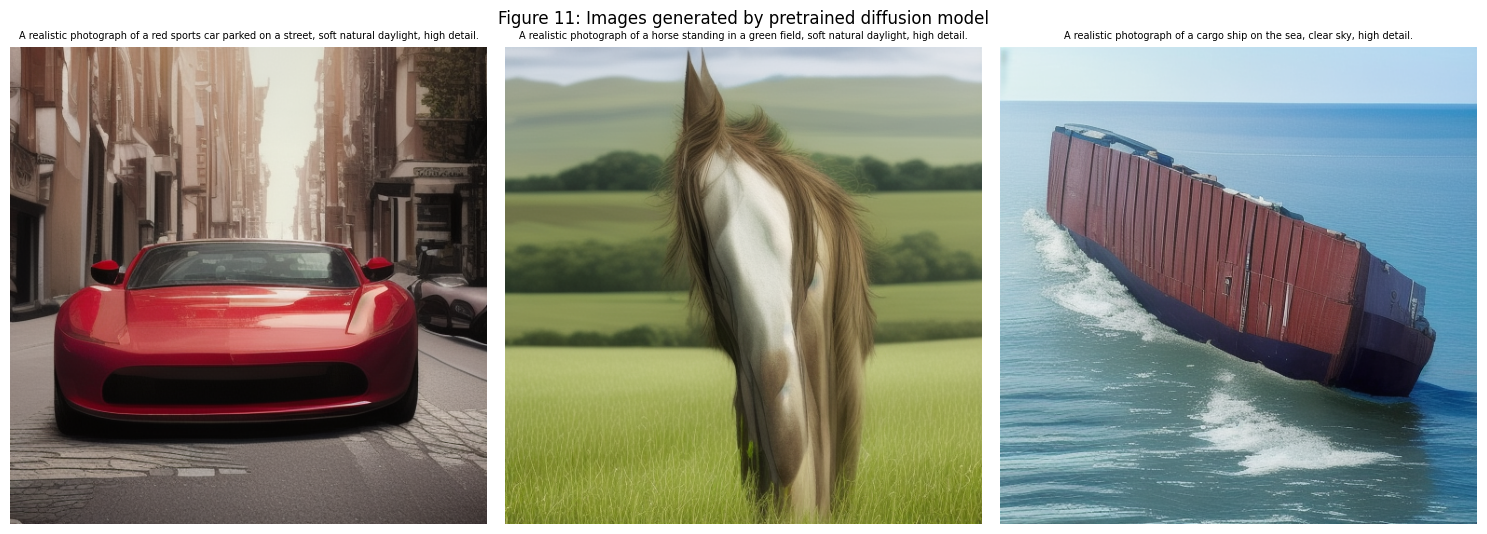

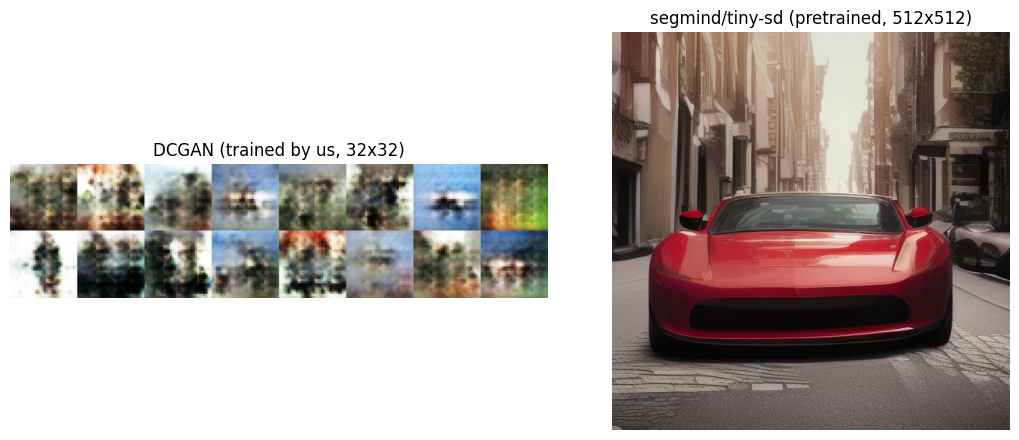

In [11]:
# CELL 8: Pretrained Diffusion model (Section 3.4, Activity B part 2)
# Inference only. First run downloads the model weights (~1 GB).
import torch
from diffusers import StableDiffusionPipeline

dev = "cuda" if torch.cuda.is_available() else "cpu"
if dev == "cpu":
    print("WARNING: no GPU. Switch Colab runtime to T4 GPU, otherwise this is very slow.")

pipe = StableDiffusionPipeline.from_pretrained(
    SD_MODEL, torch_dtype=torch.float16 if dev == "cuda" else torch.float32, safety_checker=None
).to(dev)

prompts = [
    "A realistic photograph of a red sports car parked on a street, soft natural daylight, high detail.",
    "A realistic photograph of a horse standing in a green field, soft natural daylight, high detail.",
    "A realistic photograph of a cargo ship on the sea, clear sky, high detail.",
]
sd_imgs, sd_times = [], []
_ = pipe("warm-up", num_inference_steps=2).images[0]   # warm-up so timing is not distorted
for i, p in enumerate(prompts):
    gen = torch.Generator(device=dev).manual_seed(SEED + i)
    t0 = time.time()
    im = pipe(p, num_inference_steps=SD_STEPS, guidance_scale=SD_GUIDANCE, generator=gen).images[0]
    sd_times.append(time.time() - t0)
    im.save(f"outputs/activityB_diffusion_{i + 1}.png")
    sd_imgs.append(im)
timings["Diffusion inference per image (s)"] = round(float(np.mean(sd_times)), 2)
print("Diffusion times (s):", [round(t, 2) for t in sd_times])

fig, axes = plt.subplots(1, len(sd_imgs), figsize=(5 * len(sd_imgs), 5.4))
for ax, im, p in zip(axes, sd_imgs, prompts):
    ax.imshow(im); ax.axis("off"); ax.set_title(p, fontsize=7, wrap=True)
plt.suptitle("Figure 11: Images generated by pretrained diffusion model")
plt.tight_layout(); plt.savefig("outputs/fig11_diffusion.png", dpi=150); plt.show()

# DCGAN vs Diffusion side-by-side (CO4 comparison screenshot)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
grid = np.concatenate([np.concatenate(list(final_gan[r * 8:(r + 1) * 8]), axis=1) for r in range(2)], axis=0)
axes[0].imshow(np.clip(grid, 0, 1)); axes[0].set_title("DCGAN (trained by us, 32x32)"); axes[0].axis("off")
axes[1].imshow(sd_imgs[0]); axes[1].set_title(f"{SD_MODEL} (pretrained, {sd_imgs[0].size[0]}x{sd_imgs[0].size[1]})"); axes[1].axis("off")
plt.tight_layout(); plt.savefig("outputs/activityB_comparison.png", dpi=150); plt.show()

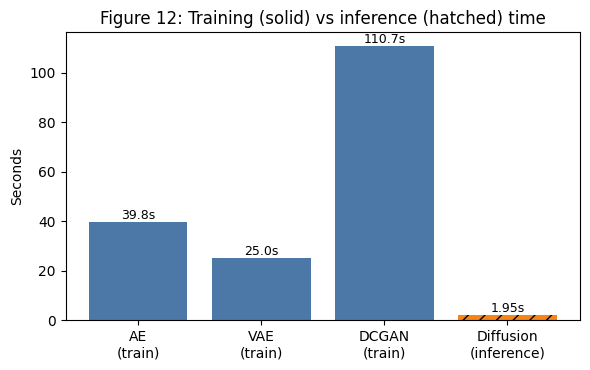


================ SUMMARY (copy into your report) ================
Dataset: CIFAR-10 | 10000 images | 32x32 RGB | train 9000 / val 1000
Settings: AE 15 ep, VAE 15 ep, DCGAN 40 ep, latent 128, noise 100; Diffusion segmind/tiny-sd, 20 steps, guidance 7.0
AE train loss first->last: (0.0475, 0.0083)
AE val loss first->last: (0.0265, 0.0086)
VAE final total / recon / KL: (631.24, 615.49, 15.76)
AE  (MSE, PSNR dB, SSIM): (0.00855, 21.15, 0.6502)
VAE (MSE, PSNR dB, SSIM): (0.02141, 17.05, 0.3429)
DCGAN final G / D loss: (2.8417, 0.6063)
AE training (s): 39.8
VAE training (s): 25.0
DCGAN training (s): 110.7
Diffusion inference per image (s): 1.95
All figures + summary.json saved in ./outputs


In [12]:
# CELL 9: Execution-time chart (Figure 12) and SUMMARY for the report
labels = ["AE\n(train)", "VAE\n(train)", "DCGAN\n(train)", "Diffusion\n(inference)"]
vals = [timings["AE training (s)"], timings["VAE training (s)"],
        timings["DCGAN training (s)"], timings["Diffusion inference per image (s)"]]
plt.figure(figsize=(6, 3.8))
bars = plt.bar(labels, vals, color=["#4C78A8", "#4C78A8", "#4C78A8", "#F58518"])
bars[3].set_hatch("//")
for b, v in zip(bars, vals):
    plt.text(b.get_x() + b.get_width() / 2, v, f"{v}s", ha="center", va="bottom", fontsize=9)
plt.ylabel("Seconds"); plt.title("Figure 12: Training (solid) vs inference (hatched) time")
plt.tight_layout(); plt.savefig("outputs/fig12_times.png", dpi=150); plt.show()

print("\n================ SUMMARY (copy into your report) ================")
print(f"Dataset: CIFAR-10 | {N_IMAGES} images | {IMG}x{IMG} RGB | train {len(x_train)} / val {len(x_val)}")
print(f"Settings: AE {EPOCHS_AE} ep, VAE {EPOCHS_VAE} ep, DCGAN {EPOCHS_GAN} ep, latent {LATENT_DIM}, "
      f"noise {NOISE_DIM}; Diffusion {SD_MODEL}, {SD_STEPS} steps, guidance {SD_GUIDANCE}")
for k, v in {**results, **timings}.items():
    print(f"{k}: {v}")
print("==================================================================")
with open("outputs/summary.json", "w") as f:
    json.dump({**{k: list(v) if isinstance(v, tuple) else v for k, v in results.items()}, **timings}, f, indent=2)
print("All figures + summary.json saved in ./outputs")

## What to write in the report (use your OWN printed numbers)
- AE: sharper, lower MSE, higher PSNR/SSIM; blur comes from MSE averaging.
- VAE: smoother/softer output because the KL term regularises the latent space; can sample new images.
- DCGAN: new but low-resolution images with artefacts; losses do not show image quality; trains slowest.
- Diffusion: far more detailed and realistic, but pretrained on huge data (not like-for-like), needs a GPU.
- Never compare AE MSE with VAE loss directly (different scales). Compare images and PSNR/SSIM instead.
- Limitations: small subset, 32x32, short training, single run, diffusion not trained by us.